# 31 — GeoMAE-ST-Wind Fine-Tuned Next-Day Prediction
## GeoMAE-inspired masked pretraining + explicit wind-aware spatial context

### Locked research framing before this experiment

The main task-specific question is:

> **Can a GeoMAE-inspired spatiotemporal representation improve next-day prediction of Emerging-3 hotspot events, where local persistence alone is weak?**

The previous `LR13` and `NodeGRU-L14` models remain **baselines**.

This notebook does **not** force GeoMAE to be declared the winner.
It uses a locked decision rule:

- **Primary task-specific metric:** Emerging-3 PR-AUC
- **Secondary metric:** overall PR-AUC
- GeoMAE is selected on performance only if its primary metric exceeds both baselines.
- If it does not, the notebook will explicitly say that superiority is not supported.

### Why this is a stronger GeoMAE downstream test than NB30

NB30 used:

```text
frozen GeoMAE encoder
        ↓
linear probe
```

NB31 uses:

```text
7 days × 3×3 patch
fire + environment + wind
        ↓
GeoMAE-inspired masked-pretrained encoder
        ↓
explicit wind-aware neighbor exposure
        ↓
end-to-end supervised fine-tuning
        ↓
regime-aware prediction head
        ↓
hotspot at t+1
```

The model therefore uses **spatial context + wind in two ways**:

1. wind U/V and wind speed are already inside the 63-token GeoMAE input;
2. an explicit source→target wind-alignment summary is fused into the downstream head.

### Evaluation discipline

- self-supervised checkpoint: pretrained through July (NB24);
- supervised architecture/epoch selection: May–July train, August development;
- September: report only as a **post-test exploratory comparison**, because September was already used in NB21/NB30;
- no September-based tuning is performed in this notebook.

In [2]:
# 1. Imports and reproducibility

from pathlib import Path
import copy
import math
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 260)

SEEDS = [11, 22, 33]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", DEVICE)
print("SEEDS :", SEEDS)

DEVICE: cpu
SEEDS : [11, 22, 33]


In [3]:
# 2. Resolve project files

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    data_path = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    checkpoint_path = (
        root
        / "model_results"
        / "geomae_spatiotemporal"
        / "t2"
        / "models"
        / "geomae_inspired_encoder.pt"
    )

    nb21_pred_path = (
        root
        / "model_results"
        / "regional_025_final_test"
        / "t2"
        / "exports"
        / "final_september_predictions.csv"
    )

    if (
        data_path.exists()
        and checkpoint_path.exists()
        and nb21_pred_path.exists()
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate regional dataset, NB24 GeoMAE checkpoint, "
        "and NB21 prediction export. Set PROJECT_ROOT manually if needed."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
    / "models"
    / "geomae_inspired_encoder.pt"
)

NB21_PRED_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_final_test"
    / "t2"
    / "exports"
    / "final_september_predictions.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_st_wind_finetuned"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"
MODEL_DIR = RESULT_DIR / "models"

for p in [
    EXPORT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR  :", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR  : c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_st_wind_finetuned\t2


In [4]:
# 3. Locked supervised configuration

# Development split
DEV_TRAIN_END = pd.Timestamp("2026-07-31")
DEV_VAL_START = pd.Timestamp("2026-08-01")
DEV_VAL_END = pd.Timestamp("2026-08-31")

# Training
BATCH_SIZE = 256
HEAD_WARMUP_EPOCHS = 2
MAX_FINETUNE_EPOCHS = 14
ONLINE_UPDATE_EPOCHS = 1

ENCODER_LR = 1e-4
HEAD_LR = 5e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.20

# Task emphasis locked before seeing NB31 result.
# Emerging-3 is the primary task-specific subgroup.
LOSS_GENERAL_WEIGHT = 0.25
LOSS_EMERGING_WEIGHT = 0.50
LOSS_PERSISTENT_WEIGHT = 0.25

# Wind context
WIND_CONTEXT_DAYS = 3
WIND_DISTANCE_SCALE_KM = 50.0
MIN_WIND_SPEED = 0.5

print("Primary selection metric: August Emerging-3 PR-AUC")
print("Secondary metric       : August overall PR-AUC")
print("Max fine-tune epochs   :", MAX_FINETUNE_EPOCHS)

Primary selection metric: August Emerging-3 PR-AUC
Secondary metric       : August overall PR-AUC
Max fine-tune epochs   : 14


In [5]:
# 4. Load checkpoint and dataset

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
    )

TOKEN_FEATURES = list(
    checkpoint["token_features"]
)

FEATURE_MEAN = {
    k: float(v)
    for k, v
    in checkpoint["feature_mean"].items()
}

FEATURE_STD = {
    k: float(v)
    for k, v
    in checkpoint["feature_std"].items()
}

TEMPORAL_DAYS = int(
    checkpoint["temporal_days"]
)

SPATIAL_OFFSETS = [
    tuple(x)
    for x in checkpoint["spatial_offsets"]
]

CENTER_TOKEN_INDEX = int(
    checkpoint["center_token_index"]
)

PRETRAIN_END = pd.Timestamp(
    checkpoint["pretrain_end"]
)

GRID_STEP = 0.25
N_SPATIAL = len(SPATIAL_OFFSETS)
N_TOKENS = TEMPORAL_DAYS * N_SPATIAL

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

required = {
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "target_fire_active_t1",
    "active_days_prev3_incl_t",
    "fire_active",
    "fire_count",
    "frp_sum",
    "wind_u_mean",
    "wind_v_mean",
    *TOKEN_FEATURES,
}

missing = sorted(
    required - set(df.columns)
)

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

print("Token features:", TOKEN_FEATURES)
print("Pretrain end  :", PRETRAIN_END.date())
print("Rows          :", len(df))
print("Cells         :", df["cell_id"].nunique())

Token features: ['temperature_mean', 'temperature_max', 'relative_humidity_mean', 'precipitation_sum', 'boundary_layer_height_mean', 'vapour_pressure_deficit_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean', 'fire_active', 'fire_count_log1p', 'frp_sum_log1p']
Pretrain end  : 2026-07-31
Rows          : 16625
Cells         : 133


## Explicit wind-aware spatial context

For every target center cell and each of the last three observed days:

1. inspect the eight neighboring 0.25° cells;
2. take the source-cell wind vector;
3. compare it with the geographic direction **source → target**;
4. keep only the positive alignment component;
5. weight neighbor hotspot activity by:
   - positive wind alignment;
   - distance decay.

This creates physically interpretable predictive context such as:

- aligned neighboring fire-active exposure;
- aligned detection-count exposure;
- aligned FRP exposure;
- nearby activity independent of wind.

It is still interpreted as **predictive spatial-wind association**, not proof of physical flame spread.

In [6]:
# 5. Geometry helpers

EARTH_RADIUS_KM = 6371.0088

def haversine_km(
    lat1,
    lon1,
    lat2,
    lon2,
):
    lat1 = np.radians(
        np.asarray(lat1, dtype=float)
    )
    lon1 = np.radians(
        np.asarray(lon1, dtype=float)
    )
    lat2 = np.radians(
        np.asarray(lat2, dtype=float)
    )
    lon2 = np.radians(
        np.asarray(lon2, dtype=float)
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2.0) ** 2
    )

    return (
        2.0
        * EARTH_RADIUS_KM
        * np.arcsin(
            np.sqrt(
                np.clip(
                    a,
                    0.0,
                    1.0,
                )
            )
        )
    )


def source_to_target_unit(
    source_lat,
    source_lon,
    target_lat,
    target_lon,
):
    mean_lat_rad = np.radians(
        (
            float(source_lat)
            + float(target_lat)
        )
        / 2.0
    )

    east_km = (
        (
            float(target_lon)
            - float(source_lon)
        )
        * 111.320
        * np.cos(mean_lat_rad)
    )

    north_km = (
        (
            float(target_lat)
            - float(source_lat)
        )
        * 110.574
    )

    norm = float(
        np.hypot(
            east_km,
            north_km,
        )
    )

    if norm == 0:
        return np.nan, np.nan

    return (
        east_km / norm,
        north_km / norm,
    )


def positive_wind_alignment(
    u,
    v,
    east_unit,
    north_unit,
):
    speed = float(
        np.hypot(
            u,
            v,
        )
    )

    if (
        not np.isfinite(speed)
        or speed < MIN_WIND_SPEED
        or not np.isfinite(east_unit)
        or not np.isfinite(north_unit)
    ):
        return 0.0

    cosine = (
        float(u) * float(east_unit)
        + float(v) * float(north_unit)
    ) / speed

    return float(
        max(
            cosine,
            0.0,
        )
    )

In [7]:
# 6. Recreate NB24 normalization and row lookup

z_cols = []

for col in TOKEN_FEATURES:
    z_col = f"z__{col}"

    mean = FEATURE_MEAN[col]
    std = FEATURE_STD[col]

    if (
        not np.isfinite(std)
        or std == 0
    ):
        std = 1.0

    df[z_col] = (
        pd.to_numeric(
            df[col],
            errors="coerce",
        )
        - mean
    ) / std

    z_cols.append(z_col)

z_matrix = (
    df[z_cols]
    .to_numpy(dtype=np.float32)
)

valid_vector = np.isfinite(
    z_matrix
).all(axis=1)

work = df.copy()

work["lat_key"] = (
    work["grid_lat"]
    .round(3)
)

work["lon_key"] = (
    work["grid_lon"]
    .round(3)
)

row_lookup = {
    (
        pd.Timestamp(row.date),
        round(float(row.lat_key), 3),
        round(float(row.lon_key), 3),
    ): idx
    for idx, row
    in work[
        [
            "date",
            "lat_key",
            "lon_key",
        ]
    ].iterrows()
}

raw_fire_active = (
    pd.to_numeric(
        work["fire_active"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

raw_fire_count_log = np.log1p(
    pd.to_numeric(
        work["fire_count"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0)
    .to_numpy(dtype=np.float32)
)

raw_frp_log = np.log1p(
    pd.to_numeric(
        work["frp_sum"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0)
    .to_numpy(dtype=np.float32)
)

raw_wind_u = (
    pd.to_numeric(
        work["wind_u_mean"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

raw_wind_v = (
    pd.to_numeric(
        work["wind_v_mean"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

print("Normalized token matrix:", z_matrix.shape)

Normalized token matrix: (16625, 13)


In [8]:
# 7. Patch + explicit wind-context builder

WIND_FEATURE_NAMES = []

for lag in range(WIND_CONTEXT_DAYS):
    WIND_FEATURE_NAMES.extend(
        [
            f"aligned_active_lag{lag}",
            f"aligned_count_lag{lag}",
            f"aligned_frp_lag{lag}",
            f"near_active_lag{lag}",
        ]
    )

N_WIND_FEATURES = len(
    WIND_FEATURE_NAMES
)

def build_sample(
    center_date,
    center_lat,
    center_lon,
):
    x = np.zeros(
        (
            N_TOKENS,
            len(TOKEN_FEATURES),
        ),
        dtype=np.float32,
    )

    valid = np.zeros(
        N_TOKENS,
        dtype=bool,
    )

    token_idx = 0

    for day_back in range(
        TEMPORAL_DAYS - 1,
        -1,
        -1,
    ):
        token_date = (
            pd.Timestamp(center_date)
            - pd.Timedelta(days=day_back)
        )

        for dx, dy in SPATIAL_OFFSETS:
            lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    token_date,
                    lat,
                    lon,
                )
            )

            if (
                idx is not None
                and valid_vector[idx]
            ):
                x[token_idx] = (
                    z_matrix[idx]
                )
                valid[token_idx] = True

            token_idx += 1

    wind_features = []

    for lag in range(
        WIND_CONTEXT_DAYS
    ):
        source_date = (
            pd.Timestamp(center_date)
            - pd.Timedelta(days=lag)
        )

        aligned_active = 0.0
        aligned_count = 0.0
        aligned_frp = 0.0
        near_active = 0.0

        for dx, dy in SPATIAL_OFFSETS:
            if dx == 0 and dy == 0:
                continue

            source_lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            source_lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    source_date,
                    source_lat,
                    source_lon,
                )
            )

            if idx is None:
                continue

            distance = float(
                haversine_km(
                    source_lat,
                    source_lon,
                    center_lat,
                    center_lon,
                )
            )

            distance_weight = float(
                np.exp(
                    -distance
                    / WIND_DISTANCE_SCALE_KM
                )
            )

            east_unit, north_unit = (
                source_to_target_unit(
                    source_lat,
                    source_lon,
                    center_lat,
                    center_lon,
                )
            )

            alignment = (
                positive_wind_alignment(
                    raw_wind_u[idx],
                    raw_wind_v[idx],
                    east_unit,
                    north_unit,
                )
            )

            wind_weight = (
                alignment
                * distance_weight
            )

            active = float(
                raw_fire_active[idx]
            )

            aligned_active += (
                active
                * wind_weight
            )

            aligned_count += (
                float(
                    raw_fire_count_log[idx]
                )
                * wind_weight
            )

            aligned_frp += (
                float(
                    raw_frp_log[idx]
                )
                * wind_weight
            )

            near_active += (
                active
                * distance_weight
            )

        wind_features.extend(
            [
                aligned_active,
                aligned_count,
                aligned_frp,
                near_active,
            ]
        )

    return (
        x,
        valid,
        np.asarray(
            wind_features,
            dtype=np.float32,
        ),
    )


print("Explicit wind features:", WIND_FEATURE_NAMES)

Explicit wind features: ['aligned_active_lag0', 'aligned_count_lag0', 'aligned_frp_lag0', 'near_active_lag0', 'aligned_active_lag1', 'aligned_count_lag1', 'aligned_frp_lag1', 'near_active_lag1', 'aligned_active_lag2', 'aligned_count_lag2', 'aligned_frp_lag2', 'near_active_lag2']


In [9]:
# 8. Build all supervised samples

min_sample_date = (
    work["date"].min()
    + pd.Timedelta(
        days=TEMPORAL_DAYS - 1
    )
)

meta_source = (
    work[
        (
            work["date"]
            >= min_sample_date
        )
        &
        (
            work[
                "target_fire_active_t1"
            ].notna()
        )
    ][
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "target_fire_active_t1",
            "active_days_prev3_incl_t",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

patches = []
valid_masks = []
wind_context = []
meta_rows = []

for row in meta_source.itertuples(
    index=False
):
    x, valid, wind = build_sample(
        row.date,
        row.grid_lat,
        row.grid_lon,
    )

    if not valid[
        CENTER_TOKEN_INDEX
    ]:
        continue

    patches.append(x)
    valid_masks.append(valid)
    wind_context.append(wind)

    meta_rows.append(
        {
            "date": pd.Timestamp(
                row.date
            ),
            "cell_id": row.cell_id,
            "grid_lat": float(
                row.grid_lat
            ),
            "grid_lon": float(
                row.grid_lon
            ),
            "target_fire_active_t1": int(
                row.target_fire_active_t1
            ),
            "active_days_prev3_incl_t": float(
                row.active_days_prev3_incl_t
            ),
        }
    )

X = np.stack(
    patches
).astype(np.float32)

VALID = np.stack(
    valid_masks
).astype(bool)

WIND = np.stack(
    wind_context
).astype(np.float32)

META = pd.DataFrame(
    meta_rows
)

print("X     :", X.shape)
print("VALID :", VALID.shape)
print("WIND  :", WIND.shape)
print("META  :", META.shape)

X     : (15827, 63, 13)
VALID : (15827, 63)
WIND  : (15827, 12)
META  : (15827, 6)


In [10]:
# 9. Standardize explicit wind features using May-July only

dev_train_mask = (
    META["date"]
    <= DEV_TRAIN_END
).to_numpy()

wind_mean = np.nanmean(
    WIND[
        dev_train_mask
    ],
    axis=0,
)

wind_std = np.nanstd(
    WIND[
        dev_train_mask
    ],
    axis=0,
)

wind_std = np.where(
    (
        np.isfinite(wind_std)
        & (wind_std > 1e-8)
    ),
    wind_std,
    1.0,
)

WIND_Z = (
    WIND
    - wind_mean
) / wind_std

WIND_Z = np.nan_to_num(
    WIND_Z,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
).astype(np.float32)

display(
    pd.DataFrame(
        {
            "feature": WIND_FEATURE_NAMES,
            "train_mean": wind_mean,
            "train_std": wind_std,
        }
    )
)

,feature,train_mean,train_std
0,aligned_active_lag0,0.087855,0.219441
1,aligned_count_lag0,0.103036,0.293723
2,aligned_frp_lag0,0.181125,0.513566
3,near_active_lag0,0.279869,0.506120
4,aligned_active_lag1,0.084070,0.214283
5,aligned_count_lag1,0.097810,0.283018
6,aligned_frp_lag1,0.171190,0.492616
7,near_active_lag1,0.268024,0.491854
8,aligned_active_lag2,0.081887,0.211442
9,aligned_count_lag2,0.094868,0.278162


In [11]:
# 10. Restore exact NB24 encoder

class SpatiotemporalMaskedEncoder(nn.Module):
    def __init__(
        self,
        n_features,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.10,
    ):
        super().__init__()

        self.n_features = n_features
        self.d_model = d_model

        self.input_proj = nn.Linear(
            n_features,
            d_model,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                d_model,
            )
        )

        self.time_embedding = nn.Embedding(
            TEMPORAL_DAYS,
            d_model,
        )

        self.space_embedding = nn.Embedding(
            N_SPATIAL,
            d_model,
        )

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=0.10,
                batch_first=True,
                norm_first=True,
                activation="gelu",
            )
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        self.reconstruction_head = nn.Linear(
            d_model,
            n_features,
        )

        token_time = []
        token_space = []

        for t in range(
            TEMPORAL_DAYS
        ):
            for s in range(
                N_SPATIAL
            ):
                token_time.append(t)
                token_space.append(s)

        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

    def encode(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.input_proj(x)

        if mask_positions is not None:
            mask_token = (
                self.mask_token.expand(
                    x.shape[0],
                    x.shape[1],
                    -1,
                )
            )

            h = torch.where(
                mask_positions.unsqueeze(-1),
                mask_token,
                h,
            )

        positional = (
            self.time_embedding(
                self.token_time
            )
            + self.space_embedding(
                self.token_space
            )
        )

        h = (
            h
            + positional.unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        return self.norm(h)

    def forward(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.encode(
            x,
            valid_mask,
            mask_positions,
        )

        recon = (
            self.reconstruction_head(
                h
            )
        )

        return recon, h


state = checkpoint[
    "model_state_dict"
]

D_MODEL = int(
    state[
        "input_proj.weight"
    ].shape[0]
)

DIM_FEEDFORWARD = int(
    state[
        "encoder.layers.0.linear1.weight"
    ].shape[0]
)

layer_numbers = []

for key in state:
    if key.startswith(
        "encoder.layers."
    ):
        parts = key.split(".")

        if len(parts) > 2:
            try:
                layer_numbers.append(
                    int(parts[2])
                )
            except ValueError:
                pass

NUM_LAYERS = (
    max(layer_numbers) + 1
    if layer_numbers
    else 2
)

NHEAD = 4

def make_pretrained_encoder():
    encoder = (
        SpatiotemporalMaskedEncoder(
            n_features=len(
                TOKEN_FEATURES
            ),
            d_model=D_MODEL,
            nhead=NHEAD,
            num_layers=NUM_LAYERS,
            dim_feedforward=(
                DIM_FEEDFORWARD
            ),
        )
    )

    encoder.load_state_dict(
        state
    )

    return encoder

test_encoder = (
    make_pretrained_encoder()
)

print("D_MODEL         :", D_MODEL)
print("NUM_LAYERS      :", NUM_LAYERS)
print("DIM_FEEDFORWARD :", DIM_FEEDFORWARD)
print("Pretrained encoder restored.")

D_MODEL         : 64
NUM_LAYERS      : 2
DIM_FEEDFORWARD : 128
Pretrained encoder restored.


## Regime-aware downstream head

The model knows whether a cell is **Emerging-eligible** at origin day `t` because this depends only on observations already available through `t`.

We therefore use:

- one auxiliary general next-day head;
- one Emerging-eligible head;
- one Persistent-context head.

This is not target leakage:
`active_days_prev3_incl_t` is known before predicting `t+1`.

The final risk score uses:
- Emerging head if recent local activity is zero;
- Persistent head otherwise.

In [12]:
# 11. GeoMAE-ST-Wind classifier

class GeoMAESTWindClassifier(nn.Module):
    def __init__(
        self,
        pretrained_encoder,
        wind_dim,
        d_model,
        dropout=0.20,
    ):
        super().__init__()

        self.encoder = (
            pretrained_encoder
        )

        self.wind_proj = nn.Sequential(
            nn.LayerNorm(
                wind_dim
            ),
            nn.Linear(
                wind_dim,
                32,
            ),
            nn.GELU(),
        )

        fusion_dim = (
            d_model
            + d_model
            + 32
        )

        self.fusion = nn.Sequential(
            nn.LayerNorm(
                fusion_dim
            ),
            nn.Linear(
                fusion_dim,
                128,
            ),
            nn.GELU(),
            nn.Dropout(
                dropout
            ),
            nn.Linear(
                128,
                64,
            ),
            nn.GELU(),
            nn.Dropout(
                dropout
            ),
        )

        self.general_head = nn.Linear(
            64,
            1,
        )

        self.emerging_head = nn.Linear(
            64,
            1,
        )

        self.persistent_head = nn.Linear(
            64,
            1,
        )

    def forward(
        self,
        x,
        valid_mask,
        wind_features,
        emerging_eligible,
    ):
        no_mask = torch.zeros_like(
            valid_mask,
            dtype=torch.bool,
        )

        h = self.encoder.encode(
            x,
            valid_mask,
            no_mask,
        )

        center_h = h[
            :,
            CENTER_TOKEN_INDEX,
            :
        ]

        valid_float = (
            valid_mask
            .unsqueeze(-1)
            .float()
        )

        global_h = (
            (
                h
                * valid_float
            ).sum(dim=1)
            / valid_float.sum(
                dim=1
            ).clamp_min(1.0)
        )

        wind_h = self.wind_proj(
            wind_features
        )

        fused = torch.cat(
            [
                center_h,
                global_h,
                wind_h,
            ],
            dim=1,
        )

        z = self.fusion(
            fused
        )

        general_logit = (
            self.general_head(z)
            .squeeze(-1)
        )

        emerging_logit = (
            self.emerging_head(z)
            .squeeze(-1)
        )

        persistent_logit = (
            self.persistent_head(z)
            .squeeze(-1)
        )

        final_logit = torch.where(
            emerging_eligible.bool(),
            emerging_logit,
            persistent_logit,
        )

        return {
            "general": general_logit,
            "emerging": emerging_logit,
            "persistent": persistent_logit,
            "final": final_logit,
        }

In [13]:
# 12. Dataset helper

class SupervisedPatchDataset(
    Dataset
):
    def __init__(
        self,
        indices,
    ):
        self.indices = np.asarray(
            indices,
            dtype=int,
        )

    def __len__(
        self,
    ):
        return len(
            self.indices
        )

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        emerging = (
            META.iloc[idx][
                "active_days_prev3_incl_t"
            ]
            == 0
        )

        y = int(
            META.iloc[idx][
                "target_fire_active_t1"
            ]
        )

        return (
            torch.from_numpy(
                X[idx]
            ),
            torch.from_numpy(
                VALID[idx]
            ),
            torch.from_numpy(
                WIND_Z[idx]
            ),
            torch.tensor(
                emerging,
                dtype=torch.bool,
            ),
            torch.tensor(
                y,
                dtype=torch.float32,
            ),
            idx,
        )

In [14]:
# 13. Loss helpers

def capped_pos_weight(
    y,
    cap=20.0,
):
    y = np.asarray(
        y,
        dtype=int,
    )

    positives = int(
        y.sum()
    )

    negatives = int(
        len(y)
        - positives
    )

    if positives == 0:
        return 1.0

    return float(
        min(
            negatives
            / positives,
            cap,
        )
    )


def make_loss_config(
    indices,
):
    meta = META.iloc[
        indices
    ]

    y = (
        meta[
            "target_fire_active_t1"
        ]
        .astype(int)
        .to_numpy()
    )

    emerging = (
        meta[
            "active_days_prev3_incl_t"
        ]
        .eq(0)
        .to_numpy()
    )

    persistent = ~emerging

    cfg = {
        "general": capped_pos_weight(
            y
        ),
        "emerging": capped_pos_weight(
            y[
                emerging
            ]
        ),
        "persistent": capped_pos_weight(
            y[
                persistent
            ]
        ),
    }

    return cfg


def compute_loss(
    outputs,
    y,
    emerging,
    loss_cfg,
):
    device = y.device

    bce_general = (
        nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                loss_cfg[
                    "general"
                ],
                device=device,
            )
        )
    )

    general_loss = bce_general(
        outputs[
            "general"
        ],
        y,
    )

    if emerging.any():
        bce_emerging = (
            nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    loss_cfg[
                        "emerging"
                    ],
                    device=device,
                )
            )
        )

        emerging_loss = (
            bce_emerging(
                outputs[
                    "emerging"
                ][
                    emerging
                ],
                y[
                    emerging
                ],
            )
        )
    else:
        emerging_loss = (
            general_loss
            * 0.0
        )

    persistent = (
        ~emerging
    )

    if persistent.any():
        bce_persistent = (
            nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    loss_cfg[
                        "persistent"
                    ],
                    device=device,
                )
            )
        )

        persistent_loss = (
            bce_persistent(
                outputs[
                    "persistent"
                ][
                    persistent
                ],
                y[
                    persistent
                ],
            )
        )
    else:
        persistent_loss = (
            general_loss
            * 0.0
        )

    total = (
        LOSS_GENERAL_WEIGHT
        * general_loss
        + LOSS_EMERGING_WEIGHT
        * emerging_loss
        + LOSS_PERSISTENT_WEIGHT
        * persistent_loss
    )

    return total

In [15]:
# 14. Prediction and metric helpers

@torch.no_grad()
def predict_indices(
    model,
    indices,
):
    dataset = (
        SupervisedPatchDataset(
            indices
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    model.eval()

    for (
        x_batch,
        valid_batch,
        wind_batch,
        emerging_batch,
        y_batch,
        idx_batch,
    ) in loader:
        x_batch = (
            x_batch
            .to(DEVICE)
        )

        valid_batch = (
            valid_batch
            .to(DEVICE)
        )

        wind_batch = (
            wind_batch
            .to(DEVICE)
        )

        emerging_batch = (
            emerging_batch
            .to(DEVICE)
        )

        outputs = model(
            x_batch,
            valid_batch,
            wind_batch,
            emerging_batch,
        )

        score = torch.sigmoid(
            outputs["final"]
        ).cpu().numpy()

        for j, idx in enumerate(
            idx_batch.numpy()
        ):
            rows.append(
                {
                    "sample_idx": int(
                        idx
                    ),
                    "score": float(
                        score[j]
                    ),
                }
            )

    pred = pd.DataFrame(
        rows
    )

    meta = (
        META.iloc[
            pred[
                "sample_idx"
            ].to_numpy()
        ]
        .reset_index(drop=True)
        .copy()
    )

    meta[
        "score"
    ] = pred[
        "score"
    ].to_numpy()

    return meta


def pr_auc_safe(
    y,
    score,
):
    y = np.asarray(
        y,
        dtype=int,
    )

    if y.sum() == 0:
        return np.nan

    return float(
        average_precision_score(
            y,
            score,
        )
    )


def evaluate_prediction_df(
    pred_df,
):
    overall_pr = pr_auc_safe(
        pred_df[
            "target_fire_active_t1"
        ],
        pred_df[
            "score"
        ],
    )

    emerging_mask = (
        pred_df[
            "active_days_prev3_incl_t"
        ].eq(0)
    )

    persistent_mask = (
        ~emerging_mask
    )

    emerging_pr = pr_auc_safe(
        pred_df.loc[
            emerging_mask,
            "target_fire_active_t1",
        ],
        pred_df.loc[
            emerging_mask,
            "score",
        ],
    )

    persistent_pr = pr_auc_safe(
        pred_df.loc[
            persistent_mask,
            "target_fire_active_t1",
        ],
        pred_df.loc[
            persistent_mask,
            "score",
        ],
    )

    return {
        "overall_pr_auc": overall_pr,
        "emerging_pr_auc": emerging_pr,
        "persistent_pr_auc": persistent_pr,
    }

In [16]:
# 15. One training epoch

def set_seed(
    seed,
):
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            seed
        )


def make_model(
    seed,
):
    set_seed(seed)

    encoder = (
        make_pretrained_encoder()
    )

    model = (
        GeoMAESTWindClassifier(
            pretrained_encoder=encoder,
            wind_dim=N_WIND_FEATURES,
            d_model=D_MODEL,
            dropout=DROPOUT,
        )
        .to(DEVICE)
    )

    return model


def make_optimizer(
    model,
):
    encoder_params = list(
        model.encoder.parameters()
    )

    head_params = [
        p
        for name, p
        in model.named_parameters()
        if not name.startswith(
            "encoder."
        )
    ]

    optimizer = torch.optim.AdamW(
        [
            {
                "params": encoder_params,
                "lr": ENCODER_LR,
            },
            {
                "params": head_params,
                "lr": HEAD_LR,
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )

    return optimizer


def train_epoch(
    model,
    indices,
    optimizer,
    loss_cfg,
    freeze_encoder=False,
):
    if freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False
    else:
        for p in model.encoder.parameters():
            p.requires_grad = True

    dataset = (
        SupervisedPatchDataset(
            indices
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    model.train()

    losses = []

    for (
        x_batch,
        valid_batch,
        wind_batch,
        emerging_batch,
        y_batch,
        _,
    ) in loader:
        x_batch = (
            x_batch
            .to(DEVICE)
        )

        valid_batch = (
            valid_batch
            .to(DEVICE)
        )

        wind_batch = (
            wind_batch
            .to(DEVICE)
        )

        emerging_batch = (
            emerging_batch
            .to(DEVICE)
        )

        y_batch = (
            y_batch
            .to(DEVICE)
        )

        optimizer.zero_grad()

        outputs = model(
            x_batch,
            valid_batch,
            wind_batch,
            emerging_batch,
        )

        loss = compute_loss(
            outputs,
            y_batch,
            emerging_batch,
            loss_cfg,
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0,
        )

        optimizer.step()

        losses.append(
            float(
                loss.detach()
                .cpu()
            )
        )

    return float(
        np.mean(losses)
    )

# PART A — August-only downstream model selection

All choices below are made from:
- May–July supervised training;
- August development evaluation.

September is not consulted for epoch selection.

In [17]:
# 16. Development indices

train_idx = np.flatnonzero(
    META[
        "date"
    ].le(
        DEV_TRAIN_END
    ).to_numpy()
)

val_idx = np.flatnonzero(
    META[
        "date"
    ].between(
        DEV_VAL_START,
        DEV_VAL_END,
    ).to_numpy()
)

print("Train rows:", len(train_idx))
print("Val rows  :", len(val_idx))

print(
    "Train positives:",
    int(
        META.iloc[
            train_idx
        ][
            "target_fire_active_t1"
        ].sum()
    ),
)

print(
    "Val positives  :",
    int(
        META.iloc[
            val_idx
        ][
            "target_fire_active_t1"
        ].sum()
    ),
)

Train rows: 10507
Val rows  : 4123
Train positives: 816
Val positives  : 2169


In [18]:
# 17. Development training across seeds

dev_history_rows = []
seed_best = {}

for seed in SEEDS:
    print()
    print("=" * 70)
    print("DEV SEED:", seed)
    print("=" * 70)

    model = make_model(
        seed
    )

    optimizer = (
        make_optimizer(
            model
        )
    )

    loss_cfg = (
        make_loss_config(
            train_idx
        )
    )

    # Head warm-up
    for warm_epoch in range(
        1,
        HEAD_WARMUP_EPOCHS + 1,
    ):
        loss = train_epoch(
            model,
            train_idx,
            optimizer,
            loss_cfg,
            freeze_encoder=True,
        )

        print(
            f"warmup {warm_epoch}/{HEAD_WARMUP_EPOCHS} | "
            f"loss={loss:.4f}"
        )

    best_state = None
    best_epoch = None
    best_emerging = -np.inf
    best_overall = -np.inf

    for epoch in range(
        1,
        MAX_FINETUNE_EPOCHS + 1,
    ):
        loss = train_epoch(
            model,
            train_idx,
            optimizer,
            loss_cfg,
            freeze_encoder=False,
        )

        val_pred = (
            predict_indices(
                model,
                val_idx,
            )
        )

        metrics = (
            evaluate_prediction_df(
                val_pred
            )
        )

        dev_history_rows.append(
            {
                "seed": seed,
                "epoch": epoch,
                "loss": loss,
                **metrics,
            }
        )

        print(
            f"epoch={epoch:02d} | "
            f"loss={loss:.4f} | "
            f"Emerging PR={metrics['emerging_pr_auc']:.4f} | "
            f"Overall PR={metrics['overall_pr_auc']:.4f}"
        )

        emerging_score = (
            metrics[
                "emerging_pr_auc"
            ]
        )

        overall_score = (
            metrics[
                "overall_pr_auc"
            ]
        )

        # Locked lexicographic rule:
        # 1) maximize Emerging PR-AUC;
        # 2) if essentially tied, prefer higher overall PR-AUC.
        improved = False

        if (
            np.isfinite(
                emerging_score
            )
            and (
                emerging_score
                > best_emerging
                + 1e-6
            )
        ):
            improved = True

        elif (
            np.isfinite(
                emerging_score
            )
            and abs(
                emerging_score
                - best_emerging
            ) <= 1e-6
            and overall_score
            > best_overall
        ):
            improved = True

        if improved:
            best_emerging = (
                emerging_score
            )

            best_overall = (
                overall_score
            )

            best_epoch = epoch

            best_state = {
                k: v.detach()
                .cpu()
                .clone()
                for k, v
                in model.state_dict().items()
            }

    seed_best[seed] = {
        "best_epoch": int(
            best_epoch
        ),
        "best_emerging_pr_auc": float(
            best_emerging
        ),
        "best_overall_pr_auc": float(
            best_overall
        ),
    }

    torch.save(
        best_state,
        MODEL_DIR
        / f"dev_best_seed{seed}.pt",
    )

dev_history = pd.DataFrame(
    dev_history_rows
)

display(
    pd.DataFrame(
        [
            {
                "seed": seed,
                **values,
            }
            for seed, values
            in seed_best.items()
        ]
    )
)


DEV SEED: 11
warmup 1/2 | loss=1.0705
warmup 2/2 | loss=0.8996
epoch=01 | loss=0.8621 | Emerging PR=0.2384 | Overall PR=0.7924
epoch=02 | loss=0.8333 | Emerging PR=0.2487 | Overall PR=0.7794
epoch=03 | loss=0.8010 | Emerging PR=0.2581 | Overall PR=0.7663
epoch=04 | loss=0.8121 | Emerging PR=0.2660 | Overall PR=0.7643
epoch=05 | loss=0.7847 | Emerging PR=0.2710 | Overall PR=0.7028
epoch=06 | loss=0.7844 | Emerging PR=0.2811 | Overall PR=0.7662
epoch=07 | loss=0.7752 | Emerging PR=0.2848 | Overall PR=0.7895
epoch=08 | loss=0.7612 | Emerging PR=0.2755 | Overall PR=0.7711
epoch=09 | loss=0.7743 | Emerging PR=0.2874 | Overall PR=0.7909
epoch=10 | loss=0.8321 | Emerging PR=0.2884 | Overall PR=0.7872
epoch=11 | loss=0.7647 | Emerging PR=0.2799 | Overall PR=0.7767
epoch=12 | loss=0.7382 | Emerging PR=0.2827 | Overall PR=0.7935
epoch=13 | loss=0.7301 | Emerging PR=0.2865 | Overall PR=0.7863
epoch=14 | loss=0.7264 | Emerging PR=0.2874 | Overall PR=0.7557

DEV SEED: 22
warmup 1/2 | loss=1.0685
w

,seed,best_epoch,best_emerging_pr_auc,best_overall_pr_auc
0,11,10,0.288439,0.787213
1,22,9,0.288123,0.755531
2,33,7,0.284612,0.768205


In [19]:
# 18. Freeze final epoch count from August development

best_epochs = [
    seed_best[
        seed
    ][
        "best_epoch"
    ]
    for seed in SEEDS
]

FINAL_FINETUNE_EPOCHS = int(
    round(
        float(
            np.median(
                best_epochs
            )
        )
    )
)

FINAL_FINETUNE_EPOCHS = max(
    FINAL_FINETUNE_EPOCHS,
    1,
)

print(
    "Seed-specific best epochs:",
    best_epochs,
)

print(
    "Frozen final fine-tune epochs:",
    FINAL_FINETUNE_EPOCHS,
)

Seed-specific best epochs: [10, 9, 7]
Frozen final fine-tune epochs: 9


# PART B — Refit through August, then rolling September scoring

The final GeoMAE downstream model is rebuilt from the same masked-pretrained checkpoint.

For each seed:
1. supervised refit using all labeled forecast origins through August 31 with the frozen epoch count;
2. for each September origin, predict `t+1`;
3. before the next origin, perform only the locked one-epoch rolling update using labels that have become available.

No future September label is used.

In [20]:
# 19. Load official LR13 / NodeGRU baseline predictions

baseline = pd.read_csv(
    NB21_PRED_PATH,
    parse_dates=[
        "origin_date",
        "forecast_date",
    ],
)

required_baseline = {
    "origin_date",
    "forecast_date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "y_true",
    "active_days_prev3_incl_t",
    "is_emerging_eligible",
    "lr13_score",
    "nodegru_l14_score",
}

missing = sorted(
    required_baseline
    - set(
        baseline.columns
    )
)

if missing:
    raise ValueError(
        "NB21 baseline export is missing:\n"
        + "\n".join(
            f"- {c}"
            for c in missing
        )
    )

TEST_ORIGINS = [
    pd.Timestamp(x)
    for x in sorted(
        baseline[
            "origin_date"
        ].unique()
    )
]

print(
    "Baseline rows:",
    len(baseline),
)

print(
    "Test origins:",
    TEST_ORIGINS[0].date(),
    "→",
    TEST_ORIGINS[-1].date(),
)

Baseline rows: 1197
Test origins: 2026-09-01 → 2026-09-09


In [21]:
# 20. Rolling GeoMAE fine-tuned prediction

seed_prediction_tables = []

for seed in SEEDS:
    print()
    print("=" * 70)
    print("FINAL ROLLING SEED:", seed)
    print("=" * 70)

    model = make_model(
        seed
    )

    optimizer = (
        make_optimizer(
            model
        )
    )

    initial_train_idx = (
        np.flatnonzero(
            META[
                "date"
            ].le(
                pd.Timestamp(
                    "2026-08-31"
                )
            ).to_numpy()
        )
    )

    loss_cfg = (
        make_loss_config(
            initial_train_idx
        )
    )

    for warm_epoch in range(
        1,
        HEAD_WARMUP_EPOCHS + 1,
    ):
        train_epoch(
            model,
            initial_train_idx,
            optimizer,
            loss_cfg,
            freeze_encoder=True,
        )

    for epoch in range(
        1,
        FINAL_FINETUNE_EPOCHS + 1,
    ):
        loss = train_epoch(
            model,
            initial_train_idx,
            optimizer,
            loss_cfg,
            freeze_encoder=False,
        )

    rows = []

    for origin_i, origin in enumerate(
        TEST_ORIGINS
    ):
        # Rolling update before predicting current origin,
        # except for the first origin because the model is
        # already fitted through August 31.
        if origin_i > 0:
            available_train_idx = (
                np.flatnonzero(
                    META[
                        "date"
                    ].le(
                        origin
                        - pd.Timedelta(
                            days=1
                        )
                    ).to_numpy()
                )
            )

            loss_cfg = (
                make_loss_config(
                    available_train_idx
                )
            )

            for _ in range(
                ONLINE_UPDATE_EPOCHS
            ):
                train_epoch(
                    model,
                    available_train_idx,
                    optimizer,
                    loss_cfg,
                    freeze_encoder=False,
                )

        pred_idx = np.flatnonzero(
            META[
                "date"
            ].eq(
                origin
            ).to_numpy()
        )

        pred = predict_indices(
            model,
            pred_idx,
        )

        pred[
            "origin_date"
        ] = origin

        pred[
            "forecast_date"
        ] = (
            origin
            + pd.Timedelta(
                days=1
            )
        )

        pred[
            "seed"
        ] = seed

        rows.append(
            pred[
                [
                    "origin_date",
                    "forecast_date",
                    "cell_id",
                    "score",
                    "seed",
                ]
            ]
        )

        print(
            origin.date(),
            "→",
            (
                origin
                + pd.Timedelta(
                    days=1
                )
            ).date(),
            "| scored cells =",
            len(pred),
        )

    seed_pred = pd.concat(
        rows,
        ignore_index=True,
    )

    seed_prediction_tables.append(
        seed_pred
    )

all_seed_predictions = pd.concat(
    seed_prediction_tables,
    ignore_index=True,
)

geomae_ensemble = (
    all_seed_predictions
    .groupby(
        [
            "origin_date",
            "forecast_date",
            "cell_id",
        ],
        as_index=False,
    )
    .agg(
        geomae_st_wind_score=(
            "score",
            "mean",
        ),
        geomae_score_std=(
            "score",
            "std",
        ),
    )
)

print(
    "Ensemble prediction rows:",
    len(
        geomae_ensemble
    ),
)


FINAL ROLLING SEED: 11
2026-09-01 → 2026-09-02 | scored cells = 133
2026-09-02 → 2026-09-03 | scored cells = 133
2026-09-03 → 2026-09-04 | scored cells = 133
2026-09-04 → 2026-09-05 | scored cells = 133
2026-09-05 → 2026-09-06 | scored cells = 133
2026-09-06 → 2026-09-07 | scored cells = 133
2026-09-07 → 2026-09-08 | scored cells = 133
2026-09-08 → 2026-09-09 | scored cells = 133
2026-09-09 → 2026-09-10 | scored cells = 133

FINAL ROLLING SEED: 22
2026-09-01 → 2026-09-02 | scored cells = 133
2026-09-02 → 2026-09-03 | scored cells = 133
2026-09-03 → 2026-09-04 | scored cells = 133
2026-09-04 → 2026-09-05 | scored cells = 133
2026-09-05 → 2026-09-06 | scored cells = 133
2026-09-06 → 2026-09-07 | scored cells = 133
2026-09-07 → 2026-09-08 | scored cells = 133
2026-09-08 → 2026-09-09 | scored cells = 133
2026-09-09 → 2026-09-10 | scored cells = 133

FINAL ROLLING SEED: 33
2026-09-01 → 2026-09-02 | scored cells = 133
2026-09-02 → 2026-09-03 | scored cells = 133
2026-09-03 → 2026-09-04 | sc

In [22]:
# 21. Merge all models on identical September rows

comparison = baseline.merge(
    geomae_ensemble,
    on=[
        "origin_date",
        "forecast_date",
        "cell_id",
    ],
    how="inner",
    validate="one_to_one",
)

print(
    "Comparison rows:",
    len(comparison),
)

print(
    "Original baseline rows:",
    len(baseline),
)

if len(
    comparison
) != len(
    baseline
):
    print(
        "WARNING: row mismatch. "
        "Interpret only the common-row comparison."
    )

Comparison rows: 1197
Original baseline rows: 1197


In [23]:
# 22. Common metric table

def safe_pr_auc(
    df,
    score_col,
):
    if (
        df[
            "y_true"
        ].sum()
        == 0
    ):
        return np.nan

    return float(
        average_precision_score(
            df[
                "y_true"
            ],
            df[
                score_col
            ],
        )
    )


def safe_roc_auc(
    df,
    score_col,
):
    if (
        df[
            "y_true"
        ].nunique()
        < 2
    ):
        return np.nan

    return float(
        roc_auc_score(
            df[
                "y_true"
            ],
            df[
                score_col
            ],
        )
    )


model_specs = [
    (
        "LR13 baseline",
        "lr13_score",
    ),
    (
        "NodeGRU-L14 baseline",
        "nodegru_l14_score",
    ),
    (
        "GeoMAE-ST-Wind fine-tuned",
        "geomae_st_wind_score",
    ),
]

overall_rows = []

for model_name, score_col in model_specs:
    overall_rows.append(
        {
            "Model": model_name,
            "Rows": len(
                comparison
            ),
            "Positives": int(
                comparison[
                    "y_true"
                ].sum()
            ),
            "PR-AUC": safe_pr_auc(
                comparison,
                score_col,
            ),
            "ROC-AUC": safe_roc_auc(
                comparison,
                score_col,
            ),
        }
    )

overall = pd.DataFrame(
    overall_rows
)

display(
    overall.sort_values(
        "PR-AUC",
        ascending=False,
    )
)

,Model,Rows,Positives,PR-AUC,ROC-AUC
0,LR13 baseline,1197,684,0.888116,0.863457
1,NodeGRU-L14 baseline,1197,684,0.882435,0.865785
2,GeoMAE-ST-Wind fine-tuned,1197,684,0.826479,0.762026


In [24]:
# 23. Primary task-specific comparison: Emerging-3

emerging_mask = (
    comparison[
        "active_days_prev3_incl_t"
    ].eq(0)
)

persistent_mask = (
    comparison[
        "active_days_prev3_incl_t"
    ].gt(0)
)

subgroup_rows = []

for model_name, score_col in model_specs:
    for context_name, mask in [
        (
            "Emerging-3 eligible",
            emerging_mask,
        ),
        (
            "Persistent-context",
            persistent_mask,
        ),
    ]:
        sub = comparison[
            mask
        ]

        subgroup_rows.append(
            {
                "Model": model_name,
                "Context": context_name,
                "Rows": len(sub),
                "Positives": int(
                    sub[
                        "y_true"
                    ].sum()
                ),
                "Prevalence": float(
                    sub[
                        "y_true"
                    ].mean()
                ),
                "PR-AUC": safe_pr_auc(
                    sub,
                    score_col,
                ),
                "ROC-AUC": safe_roc_auc(
                    sub,
                    score_col,
                ),
            }
        )

subgroups = pd.DataFrame(
    subgroup_rows
)

display(subgroups)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,ROC-AUC
0,LR13 baseline,Emerging-3 eligible,252,28,0.111111,0.289877,0.709104
1,LR13 baseline,Persistent-context,945,656,0.694180,0.897755,0.798609
2,NodeGRU-L14 baseline,Emerging-3 eligible,252,28,0.111111,0.326900,0.742506
3,NodeGRU-L14 baseline,Persistent-context,945,656,0.694180,0.891270,0.800337
4,GeoMAE-ST-Wind fine-tuned,Emerging-3 eligible,252,28,0.111111,0.262596,0.699936
5,GeoMAE-ST-Wind fine-tuned,Persistent-context,945,656,0.694180,0.886900,0.786765


In [25]:
# 24. Task-specific deltas and locked selection rule

overall_lookup = (
    overall
    .set_index(
        "Model"
    )
)

sub_lookup = (
    subgroups
    .pivot(
        index="Model",
        columns="Context",
        values="PR-AUC",
    )
)

geo_name = (
    "GeoMAE-ST-Wind fine-tuned"
)

baseline_names = [
    "LR13 baseline",
    "NodeGRU-L14 baseline",
]

delta_rows = []

for baseline_name in baseline_names:
    delta_rows.append(
        {
            "Comparison": (
                geo_name
                + " - "
                + baseline_name
            ),
            "Delta Emerging PR-AUC": (
                sub_lookup.loc[
                    geo_name,
                    "Emerging-3 eligible",
                ]
                - sub_lookup.loc[
                    baseline_name,
                    "Emerging-3 eligible",
                ]
            ),
            "Delta Overall PR-AUC": (
                overall_lookup.loc[
                    geo_name,
                    "PR-AUC",
                ]
                - overall_lookup.loc[
                    baseline_name,
                    "PR-AUC",
                ]
            ),
            "Delta Persistent PR-AUC": (
                sub_lookup.loc[
                    geo_name,
                    "Persistent-context",
                ]
                - sub_lookup.loc[
                    baseline_name,
                    "Persistent-context",
                ]
            ),
        }
    )

deltas = pd.DataFrame(
    delta_rows
)

display(deltas)

geo_emerging = float(
    sub_lookup.loc[
        geo_name,
        "Emerging-3 eligible",
    ]
)

best_baseline_emerging = float(
    max(
        sub_lookup.loc[
            baseline_name,
            "Emerging-3 eligible",
        ]
        for baseline_name
        in baseline_names
    )
)

PERFORMANCE_SELECTION_SUPPORTED = (
    geo_emerging
    > best_baseline_emerging
)

print()
print(
    "Locked primary task:",
    "Emerging-3 next-day prediction",
)

print(
    "GeoMAE Emerging PR-AUC:",
    round(
        geo_emerging,
        6,
    ),
)

print(
    "Best baseline Emerging PR-AUC:",
    round(
        best_baseline_emerging,
        6,
    ),
)

print()

if PERFORMANCE_SELECTION_SUPPORTED:
    print(
        "✅ PERFORMANCE-BASED SELECTION SUPPORTED:"
    )
    print(
        "GeoMAE-ST-Wind exceeds both baselines on the locked primary task-specific metric."
    )
else:
    print(
        "⚠️ PERFORMANCE-BASED SELECTION NOT SUPPORTED:"
    )
    print(
        "The current experiment does not justify claiming GeoMAE is superior on the locked primary metric."
    )

,Comparison,Delta Emerging PR-AUC,Delta Overall PR-AUC,Delta Persistent PR-AUC
0,GeoMAE-ST-Wind fine-tuned - LR13 baseline,-0.027281,-0.061637,-0.010855
1,GeoMAE-ST-Wind fine-tuned - NodeGRU-L14 baseline,-0.064304,-0.055956,-0.004370



Locked primary task: Emerging-3 next-day prediction
GeoMAE Emerging PR-AUC: 0.262596
Best baseline Emerging PR-AUC: 0.3269

⚠️ PERFORMANCE-BASED SELECTION NOT SUPPORTED:
The current experiment does not justify claiming GeoMAE is superior on the locked primary metric.


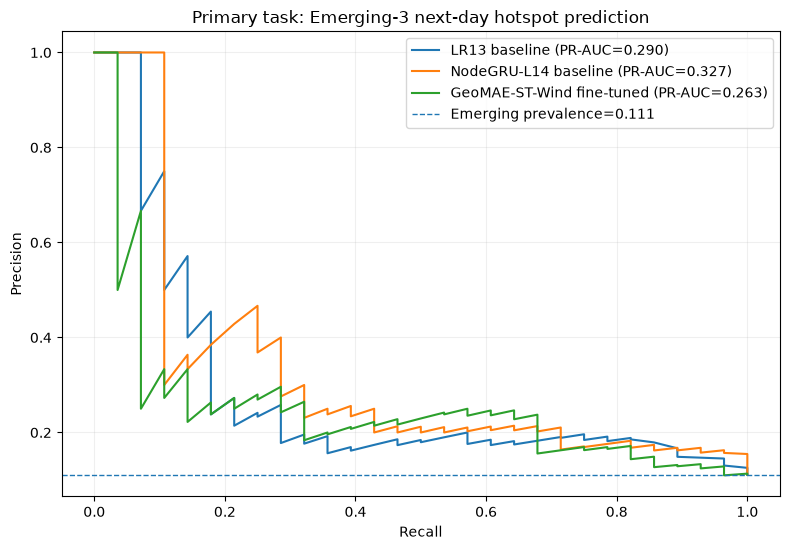

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_st_wind_finetuned\t2\figures\01_primary_emerging_pr_curve.png


In [26]:
# 25. Precision-Recall curve for the PRIMARY Emerging-3 task

emerging_df = comparison[
    emerging_mask
].copy()

fig, ax = plt.subplots(
    figsize=(8, 5.6)
)

for model_name, score_col in model_specs:
    p, r, _ = precision_recall_curve(
        emerging_df[
            "y_true"
        ],
        emerging_df[
            score_col
        ],
    )

    pr = average_precision_score(
        emerging_df[
            "y_true"
        ],
        emerging_df[
            score_col
        ],
    )

    ax.plot(
        r,
        p,
        label=(
            f"{model_name} "
            f"(PR-AUC={pr:.3f})"
        ),
    )

prevalence = float(
    emerging_df[
        "y_true"
    ].mean()
)

ax.axhline(
    prevalence,
    linestyle="--",
    linewidth=1,
    label=(
        f"Emerging prevalence="
        f"{prevalence:.3f}"
    ),
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    "Primary task: Emerging-3 next-day hotspot prediction"
)

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "01_primary_emerging_pr_curve.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

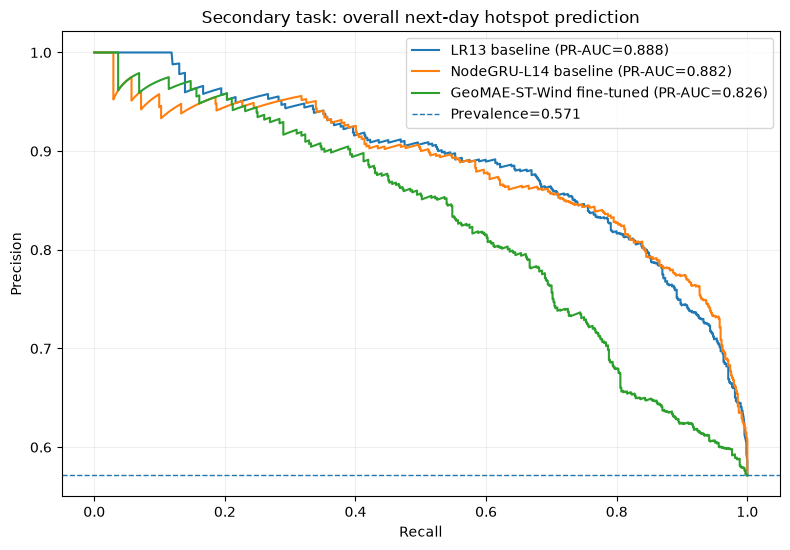

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_st_wind_finetuned\t2\figures\02_overall_pr_curve.png


In [27]:
# 26. Overall PR curve as secondary evaluation

fig, ax = plt.subplots(
    figsize=(8, 5.6)
)

for model_name, score_col in model_specs:
    p, r, _ = precision_recall_curve(
        comparison[
            "y_true"
        ],
        comparison[
            score_col
        ],
    )

    pr = average_precision_score(
        comparison[
            "y_true"
        ],
        comparison[
            score_col
        ],
    )

    ax.plot(
        r,
        p,
        label=(
            f"{model_name} "
            f"(PR-AUC={pr:.3f})"
        ),
    )

prevalence = float(
    comparison[
        "y_true"
    ].mean()
)

ax.axhline(
    prevalence,
    linestyle="--",
    linewidth=1,
    label=f"Prevalence={prevalence:.3f}",
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    "Secondary task: overall next-day hotspot prediction"
)

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "02_overall_pr_curve.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

In [28]:
# 27. Recall@K for Emerging-positive operational ranking

K_VALUES = [
    10,
    20,
    30,
    50,
]

rank_rows = []

for forecast_date, day in comparison.groupby(
    "forecast_date"
):
    eligible = day[
        day[
            "active_days_prev3_incl_t"
        ].eq(0)
    ].copy()

    positives = int(
        eligible[
            "y_true"
        ].sum()
    )

    if positives == 0:
        continue

    for model_name, score_col in model_specs:
        ranked = (
            eligible
            .sort_values(
                score_col,
                ascending=False,
            )
            .reset_index(drop=True)
        )

        for k in K_VALUES:
            top = ranked.head(k)

            captured = int(
                top[
                    "y_true"
                ].sum()
            )

            rank_rows.append(
                {
                    "forecast_date": forecast_date,
                    "Model": model_name,
                    "K": k,
                    "Emerging positives": positives,
                    "Captured": captured,
                    "Recall@K": (
                        captured
                        / positives
                    ),
                }
            )

recall_at_k = pd.DataFrame(
    rank_rows
)

recall_at_k_summary = (
    recall_at_k
    .groupby(
        [
            "Model",
            "K",
        ],
        as_index=False,
    )
    .agg(
        mean_recall_at_k=(
            "Recall@K",
            "mean",
        ),
        median_recall_at_k=(
            "Recall@K",
            "median",
        ),
    )
)

display(
    recall_at_k_summary
)

,Model,K,mean_recall_at_k,median_recall_at_k
0,GeoMAE-ST-Wind fine-tuned,10,0.576786,0.500000
1,GeoMAE-ST-Wind fine-tuned,20,0.854167,1.000000
2,GeoMAE-ST-Wind fine-tuned,30,0.968750,1.000000
3,GeoMAE-ST-Wind fine-tuned,50,1.000000,1.000000
4,LR13 baseline,10,0.683929,0.535714
5,LR13 baseline,20,0.909226,1.000000
6,LR13 baseline,30,1.000000,1.000000
7,LR13 baseline,50,1.000000,1.000000
8,NodeGRU-L14 baseline,10,0.677679,0.585714
9,NodeGRU-L14 baseline,20,0.922917,1.000000


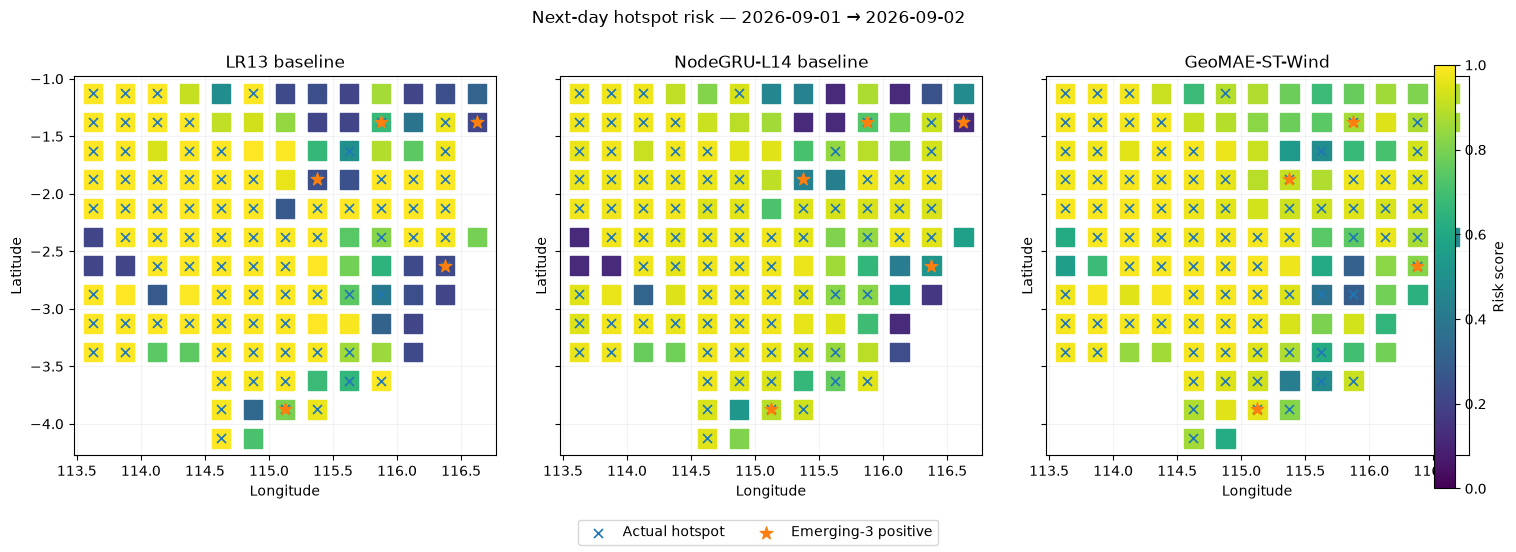

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_st_wind_finetuned\t2\figures\03_three_model_sep02_map.png


In [29]:
# 28. Three-model map for 2026-09-02

MAP_FORECAST_DATE = pd.Timestamp(
    "2026-09-02"
)

day_map = comparison[
    comparison[
        "forecast_date"
    ].eq(
        MAP_FORECAST_DATE
    )
].copy()

if day_map.empty:
    raise ValueError(
        "No comparison rows for selected map date."
    )

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5.5),
    sharex=True,
    sharey=True,
)

map_specs = [
    (
        axes[0],
        "lr13_score",
        "LR13 baseline",
    ),
    (
        axes[1],
        "nodegru_l14_score",
        "NodeGRU-L14 baseline",
    ),
    (
        axes[2],
        "geomae_st_wind_score",
        "GeoMAE-ST-Wind",
    ),
]

for ax, score_col, title in map_specs:
    sc = ax.scatter(
        day_map[
            "grid_lon"
        ],
        day_map[
            "grid_lat"
        ],
        c=day_map[
            score_col
        ],
        marker="s",
        s=180,
        vmin=0,
        vmax=1,
    )

    actual = day_map[
        day_map[
            "y_true"
        ].eq(1)
    ]

    emerging_actual = actual[
        actual[
            "active_days_prev3_incl_t"
        ].eq(0)
    ]

    ax.scatter(
        actual[
            "grid_lon"
        ],
        actual[
            "grid_lat"
        ],
        marker="x",
        s=42,
        linewidths=1.2,
        label="Actual hotspot",
    )

    if len(
        emerging_actual
    ):
        ax.scatter(
            emerging_actual[
                "grid_lon"
            ],
            emerging_actual[
                "grid_lat"
            ],
            marker="*",
            s=95,
            linewidths=0.8,
            label="Emerging-3 positive",
        )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.15)

fig.colorbar(
    sc,
    ax=axes.ravel().tolist(),
    fraction=0.025,
    pad=0.02,
    label="Risk score",
)

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
)

fig.suptitle(
    (
        "Next-day hotspot risk — "
        f"{day_map['origin_date'].iloc[0].date()}"
        f" → {MAP_FORECAST_DATE.date()}"
    )
)

fig.subplots_adjust(
    bottom=0.17,
    top=0.86,
    wspace=0.15,
)

path = (
    FIGURE_DIR
    / "03_three_model_sep02_map.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

In [30]:
# 29. Export results

dev_history.to_csv(
    EXPORT_DIR
    / "august_dev_history.csv",
    index=False,
)

pd.DataFrame(
    [
        {
            "seed": seed,
            **values,
        }
        for seed, values
        in seed_best.items()
    ]
).to_csv(
    EXPORT_DIR
    / "august_seed_best_epochs.csv",
    index=False,
)

all_seed_predictions.to_csv(
    EXPORT_DIR
    / "september_seed_predictions.csv",
    index=False,
)

comparison.to_csv(
    EXPORT_DIR
    / "september_three_model_predictions.csv",
    index=False,
)

overall.to_csv(
    EXPORT_DIR
    / "overall_comparison.csv",
    index=False,
)

subgroups.to_csv(
    EXPORT_DIR
    / "subgroup_comparison.csv",
    index=False,
)

deltas.to_csv(
    EXPORT_DIR
    / "geomae_deltas.csv",
    index=False,
)

recall_at_k.to_csv(
    EXPORT_DIR
    / "emerging_recall_at_k_daily.csv",
    index=False,
)

recall_at_k_summary.to_csv(
    EXPORT_DIR
    / "emerging_recall_at_k_summary.csv",
    index=False,
)

print(
    "Saved outputs to:",
    EXPORT_DIR,
)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_st_wind_finetuned\t2\exports


In [ ]:
# 30. Automatic thesis/supervisor summary

geo_overall = float(
    overall_lookup.loc[
        geo_name,
        "PR-AUC",
    ]
)

geo_emerging = float(
    sub_lookup.loc[
        geo_name,
        "Emerging-3 eligible",
    ]
)

geo_persistent = float(
    sub_lookup.loc[
        geo_name,
        "Persistent-context",
    ]
)

print(
    "=== NB31 GEOMAE-ST-WIND FINE-TUNED NEXT-DAY ==="
)
print()

print("MODEL")
print("- GeoMAE-inspired masked-pretrained Transformer")
print("- 7-day × 3×3 spatiotemporal patch")
print("- fire + environmental + wind token channels")
print("- explicit source→target wind-aligned neighbor exposure")
print("- supervised end-to-end fine-tuning")
print("- regime-aware Emerging/Persistent downstream heads")
print()

print("LOCKED PRIMARY TASK")
print("- Emerging-3 next-day hotspot prediction")
print("- Primary metric: Emerging-3 PR-AUC")
print("- Overall PR-AUC is secondary")
print()

print("RESULTS")
print(
    "GeoMAE Emerging PR-AUC  :",
    round(
        geo_emerging,
        6,
    ),
)

print(
    "GeoMAE Overall PR-AUC   :",
    round(
        geo_overall,
        6,
    ),
)

print(
    "GeoMAE Persistent PR-AUC:",
    round(
        geo_persistent,
        6,
    ),
)

print()
print("BASELINE DELTAS")
display(deltas)
print()

if PERFORMANCE_SELECTION_SUPPORTED:
    print(
        "✅ Thesis wording supported by the locked primary metric:"
    )
    print(
        "'GeoMAE-ST-Wind was selected as the main model because it achieved the highest PR-AUC on the primary Emerging-3 next-day prediction task, while LR13 and NodeGRU-L14 were retained as baselines.'"
    )
else:
    print(
        "⚠️ Do NOT write that GeoMAE is superior based on performance."
    )
    print(
        "The current results do not support that claim on the locked primary metric."
    )

print()
print("GUARDRAILS")
print("- September is a post-test exploratory comparison, not a new untouched final test.")
print("- Raw scores are ranking/risk scores, not calibrated probabilities.")
print("- Wind alignment is predictive context, not proof of physical fire spread.")

=== NB31 GEOMAE-ST-WIND FINE-TUNED NEXT-DAY ===

MODEL
- GeoMAE-inspired masked-pretrained Transformer
- 7-day × 3×3 spatiotemporal patch
- fire + environmental + wind token channels
- explicit source→target wind-aligned neighbor exposure
- supervised end-to-end fine-tuning
- regime-aware Emerging/Persistent downstream heads

LOCKED PRIMARY TASK
- Emerging-3 next-day hotspot prediction
- Primary metric: Emerging-3 PR-AUC
- Overall PR-AUC is secondary

RESULTS
GeoMAE Emerging PR-AUC  : 0.262596
GeoMAE Overall PR-AUC   : 0.826479
GeoMAE Persistent PR-AUC: 0.8869

BASELINE DELTAS


,Comparison,Delta Emerging PR-AUC,Delta Overall PR-AUC,Delta Persistent PR-AUC
0,GeoMAE-ST-Wind fine-tuned - LR13 baseline,-0.027281,-0.061637,-0.010855
1,GeoMAE-ST-Wind fine-tuned - NodeGRU-L14 baseline,-0.064304,-0.055956,-0.004370



⚠️ Do NOT write that GeoMAE is superior based on performance.
The current results do not support that claim on the locked primary metric.

GUARDRAILS
- September is a post-test exploratory comparison, not a new untouched final test.
- Raw scores are ranking/risk scores, not calibrated probabilities.
- Wind alignment is predictive context, not proof of physical fire spread.


: 

# What to send after Run All

Please send:

1. **Cell 18** — frozen fine-tune epoch count;
2. **Cell 22** — overall comparison;
3. **Cell 23** — Emerging/Persistent comparison;
4. **Cell 24** — delta + automatic selection statement;
5. **Cell 25** — Emerging PR curve;
6. **Cell 27** — Recall@K table;
7. **Cell 28** — three-model map;
8. **Cell 30** — automatic supervisor summary.

If GeoMAE wins the locked Emerging-3 metric, the next notebook should be a clean ablation:

- Transformer-ST-Wind from scratch;
- GeoMAE-ST without explicit wind context;
- GeoMAE-ST-Wind.

That is what can demonstrate whether the gain comes from:
**masked pretraining**, **spatial context**, and **wind-aware context**.